# Exercise 3: Working with Gensim for Word2Vec Models and Embeddings

## Introduction to Gensim and Word2Vec

Gensim is a powerful library for natural language processing (NLP) and machine learning that focuses on topic modeling, document similarity, and vector space modeling. It is widely used to learn, manipulate, and perform various operations with word embeddings. Word embeddings are dense vector representations of words, where semantically similar words are closer to each other in vector space.

In this exercise, you'll train a **Skip-gram** Word2Vec model using Gensim on a large text corpus, visualize the learned embeddings, and explore some advanced features like similarity queries and loading pretrained embeddings.

## Task 1: Training a Skip-gram Word2Vec Model

Use the provided code to train a Word2Vec model on a large text corpus. The model will be trained using the Skip-gram approach, and the key parameters include:
- `vector_size`: The dimensionality of the word vectors (default: 100).
- `window`: The maximum distance between the current and predicted word within a sentence (default: 5).
- `sg`: Skip-gram model (set to 1).
- `epochs`: The number of training iterations (default: 5).
- `batch_words`: Number of words to process per batch (default: 10,000).

Once trained, the model will be saved as `skipgram_word2vec.model`. The exercise will involve inspecting the vocabulary, using the embeddings for word similarity tasks, and exploring other capabilities.

### Steps:
1. **Train the Skip-gram Word2Vec model** using the `train_skipgram_on_large_corpus()` function provided.
2. **Print the vocabulary** of the trained model.
3. **Learn word vectors**: Find the vector representation of specific words.
4. **Query most similar words**: Use the model to find the most similar words to a given word.
5. **Find most similar sentences**: Compare sentences by finding the most similar ones in terms of word vectors.

## Task 2: Visualizing Word Embeddings in 3D using TensorBoard

Once you've trained your Word2Vec model, visualize the learned word vectors in 3D using **TensorBoard**. The goal is to reduce the dimensionality of the word embeddings to 3D (using techniques like PCA) and plot them on a TensorBoard graph to inspect how the words cluster based on their semantic similarity.

### Steps:
1. Reduce the word embeddings to 3D using PCA.
2. Log the embeddings to TensorBoard.
3. Launch TensorBoard to inspect the word embeddings in 3D space.

## Task 3: Loading Pretrained Word Embeddings from Facebook

Gensim allows you to load pretrained word embeddings. In this task, you'll load the **FastText embeddings** pretrained by Facebook for both English and Arabic. These embeddings have been trained on a large corpus of text and can be used to perform word similarity, analogy tasks, and more. Gensim provides easy access to these pretrained embeddings.

### Steps:
1. Download the pretrained FastText word embeddings from Facebook (english and Arabic 300 size vectors).
Link: https://fasttext.cc/docs/en/crawl-vectors.html
2. Load the embeddings using Gensim’s `KeyedVectors` class.
3. Query the pretrained embeddings for the most similar words to a given word.



In [1]:
# Install necessary libraries if not already installed 

In [2]:
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
import multiprocessing

def train_skipgram_on_large_corpus(corpus_path, vector_size=100, window=5, sg=1, epochs=5, batch_words=10000):
    """
    Trains a skip-gram Word2Vec model on a large text corpus using Gensim, optimized for GPU if available.

    Args:
        corpus_path (str): Path to the text corpus file (e.g., a .txt file with large text data).
        vector_size (int): Dimensionality of the word vectors (default: 100).
        window (int): Maximum distance between the current and predicted word within a sentence (default: 5).
        sg (int): Defines the training algorithm. 1 for skip-gram; 0 for CBOW (default: 1, skip-gram).
        epochs (int): Number of training iterations over the entire corpus (default: 5).
        batch_words (int): Number of words to process per batch (default: 10,000).

    Returns:
        model (gensim.models.Word2Vec): Trained Word2Vec model containing word embeddings.
    """
    import os
    from gensim.models.word2vec import LineSentence

    # Ensure the corpus file exists
    if not os.path.exists(corpus_path):
        raise FileNotFoundError(f"Corpus file '{corpus_path}' not found!")

    # Load the corpus using LineSentence for memory efficiency
    # LineSentence processes one line of text at a time, which is ideal for large corpora
    sentences = LineSentence(corpus_path)

    # Configure the Word2Vec model
    model = Word2Vec(
        sentences=sentences,       # The processed sentences
        vector_size=vector_size,   # Size of word embeddings
        window=window,             # Context window size
        sg=sg,                     # Use skip-gram (sg=1) or CBOW (sg=0)
        workers=multiprocessing.cpu_count(),  # Use all available CPU cores
        epochs=epochs,             # Number of training epochs
        batch_words=batch_words,   # Number of words processed per batch
        compute_loss=True          # Enable loss tracking
    )

    # Save the model for later use
    model.save("skipgram_word2vec.model")
    print("Model training completed and saved as 'skipgram_word2vec.model'.")
    return model

# Example usage:
train_skipgram_on_large_corpus("TED2013.ar-en.en")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Model training completed and saved as 'skipgram_word2vec.model'.


In [3]:
# Load the saved Word2Vec model
model = Word2Vec.load("skipgram_word2vec.model")

In [4]:
# Print the vocabulary of the trained model.
vocab = model.wv.key_to_index
print(f"Total vocabulary size: {len(vocab):,} words")
print("\nFirst 50 words in the vocabulary:")
print(list(vocab.keys())[:50])


Total vocabulary size: 24,879 words

First 50 words in the vocabulary:
['the', 'to', 'of', 'a', 'and', 'that', 'in', 'I', 'is', 'you', 'And', 'we', 'this', 'it', '--', 'was', 'for', 'have', 'are', 'on', 'with', 'they', 'can', 'about', 'what', 'be', 'at', 'as', 'So', 'all', 'not', 'do', 'from', 'my', "it's", 'so', 'one', 'like', 'an', 'just', 'but', 'people', 'if', 'very', 'But', 'our', 'or', 'these', 'The', 'going']


TensorBoard 3D embeddings logged to: logs/word2vec
To inspect in TensorBoard, run in terminal: tensorboard --logdir logs/word2vec


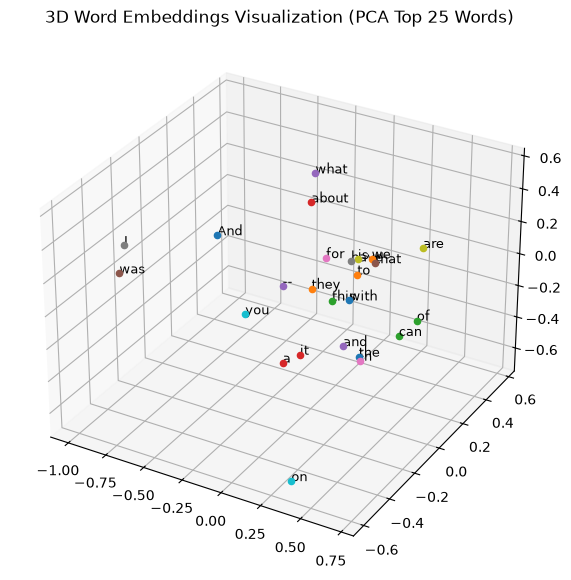

In [5]:
# visualize the learned word vectors in 3D using TensorBoard. The goal is to reduce the dimensionality of the word embeddings to 3D
# (using techniques like PCA) and plot them on a TensorBoard graph to inspect how the words cluster based on their semantic similarity.

import os
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorboard.plugins import projector

log_dir = "logs/word2vec"
os.makedirs(log_dir, exist_ok=True)

# Select top words for 3D visualization
num_words = 1000
words = list(model.wv.index_to_key)[:num_words]
vectors = model.wv[words]

# 1. Reduce embeddings to 3D using PCA
pca = PCA(n_components=3, random_state=42)
reduced_vectors = pca.fit_transform(vectors)

# 2. Save metadata (labels) for TensorBoard
metadata_path = os.path.join(log_dir, "metadata.tsv")
with open(metadata_path, "w", encoding="utf-8") as f:
    for word in words:
        f.write(f"{word}\n")

# 3. Save 3D vectors as a checkpoint
weights = tf.Variable(reduced_vectors, name="word_embeddings_3d")
checkpoint = tf.train.Checkpoint(embedding=weights)
checkpoint.save(os.path.join(log_dir, "embedding.ckpt"))

# 4. Configure TensorBoard Projector
config = projector.ProjectorConfig()
embedding = config.embeddings.add()
embedding.tensor_name = "embedding/.ATTRIBUTES/VARIABLE_VALUE"
embedding.metadata_path = "metadata.tsv"
projector.visualize_embeddings(log_dir, config)

print(f"TensorBoard 3D embeddings logged to: {log_dir}")
print("To inspect in TensorBoard, run in terminal: tensorboard --logdir logs/word2vec")

# Inline 3D visualization of sample words
sample_idx = list(range(25))
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
for idx in sample_idx:
    x, y, z = reduced_vectors[idx]
    ax.scatter(x, y, z)
    ax.text(x, y, z, words[idx], fontsize=9)
ax.set_title("3D Word Embeddings Visualization (PCA Top 25 Words)")
plt.show()


In [6]:
queries_words = [
    "spaghetti", "novel", "cloudy", "jogging", "hue", "studying", "temperature",
    "basketball", "pasta", "cinema", "programming", "literature", "baseball",
    "exhausted", "hobby"
]

corpus_words = [
    "I", "love", "pizza", "I", "adore", "pizza", "She", "enjoys", "a", "good", "book",
    "Reading", "is", "my", "hobby", "The", "cat", "is", "on", "the", "mat", "A", "dog",
    "barks", "loudly", "He", "loves", "playing", "soccer", "We", "are", "going", "to",
    "the", "park", "The", "weather", "is", "beautiful", "today", "My", "favorite", "color",
    "is", "blue", "I", "feel", "tired", "today", "I", "hate", "waiting", "in", "line",
    "She", "hates", "tomatoes", "I", "enjoy", "watching", "movies", "Music", "is", "my",
    "passion", "My", "friend", "is", "funny", "The", "sky", "is", "clear", "tonight",
    "I", "am", "learning", "Python", "Coding", "is", "fun", "This", "is", "a", "great",
    "place", "to", "visit"
]

# For each query word, find the 3 closest words in the corpus and print them along with their similarity scores.
unique_corpus = sorted(list(set(corpus_words)))

for query in queries_words:
    # Resolve vocabulary key (handle case-sensitivity)
    target_q = query if query in model.wv else (query.lower() if query.lower() in model.wv else None)
    if target_q is None:
        print(f"Query: '{query}' -> Not in model vocabulary.")
        continue

    similarities = []
    for c_word in unique_corpus:
        target_c = c_word if c_word in model.wv else (c_word.lower() if c_word.lower() in model.wv else None)
        if target_c:
            sim = model.wv.similarity(target_q, target_c)
            similarities.append((c_word, round(float(sim), 4)))

    similarities.sort(key=lambda x: x[1], reverse=True)
    top_3 = similarities[:3]
    print(f"Query: '{query}'")
    for match_word, score in top_3:
        print(f"   -> '{match_word}' (similarity: {score})")


Query: 'spaghetti'
   -> 'Reading' (similarity: 0.7709)
   -> 'hates' (similarity: 0.7634)
   -> 'enjoys' (similarity: 0.7078)
Query: 'novel'
   -> 'Reading' (similarity: 0.7055)
   -> 'Music' (similarity: 0.6923)
   -> 'hobby' (similarity: 0.6686)
Query: 'cloudy'
   -> 'tomatoes' (similarity: 0.8599)
   -> 'mat' (similarity: 0.8449)
   -> 'Reading' (similarity: 0.7849)
Query: 'jogging' -> Not in model vocabulary.
Query: 'hue' -> Not in model vocabulary.
Query: 'studying'
   -> 'watching' (similarity: 0.5913)
   -> 'Coding' (similarity: 0.5847)
   -> 'Reading' (similarity: 0.5786)
Query: 'temperature'
   -> 'mat' (similarity: 0.6215)
   -> 'weather' (similarity: 0.5996)
   -> 'tomatoes' (similarity: 0.5871)
Query: 'basketball'
   -> 'mat' (similarity: 0.8734)
   -> 'pizza' (similarity: 0.8658)
   -> 'Reading' (similarity: 0.8605)
Query: 'pasta' -> Not in model vocabulary.
Query: 'cinema'
   -> 'Reading' (similarity: 0.8613)
   -> 'hates' (similarity: 0.8567)
   -> 'loudly' (similarity:

In [7]:
queries = [
    "I like pasta",
    "What is your favorite book?",
    "Is it a nice day?",
    "My dog loves to run",
    "What color do you like?",
    "What are you reading?",
    "How's the weather outside?",
    "I enjoy football",
    "Do you like pizza?",
    "I want to watch a movie",
    "Tell me about Python programming",
    "Do you enjoy books?",
    "Are you a fan of soccer?",
    "I feel so tired today",
    "Can you recommend a good hobby?"
]

corpus = [
    "I love pizza",
    "I adore pizza",
    "She enjoys a good book",
    "Reading is my hobby",
    "The cat is on the mat",
    "A dog barks loudly",
    "He loves playing soccer",
    "We are going to the park",
    "The weather is beautiful today",
    "My favorite color is blue",
    "I feel tired today",
    "I hate waiting in line",
    "She hates tomatoes",
    "I enjoy watching movies",
    "Music is my passion",
    "My friend is funny",
    "The sky is clear tonight",
    "I am learning Python",
    "Coding is fun",
    "This is a great place to visit"
]

# For each query, find the 3 closest phrases in the corpus and print them along with their similarity scores.
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def get_sentence_vector(sentence, model):
    tokens = [w.strip("?,.!\"'") for w in sentence.split()]
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    if not vectors:
        vectors = [model.wv[w.lower()] for w in tokens if w.lower() in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

corpus_vectors = np.array([get_sentence_vector(s, model) for s in corpus])

for q in queries:
    q_vec = get_sentence_vector(q, model).reshape(1, -1)
    sims = cosine_similarity(q_vec, corpus_vectors)[0]
    top_indices = np.argsort(sims)[::-1][:3]
    print(f"Query: \"{q}\"")
    for idx in top_indices:
        print(f"   -> \"{corpus[idx]}\" (similarity: {round(float(sims[idx]), 4)})")


Query: "I like pasta"
   -> "I love pizza" (similarity: 0.8117)
   -> "I adore pizza" (similarity: 0.8036)
   -> "I enjoy watching movies" (similarity: 0.7633)
Query: "What is your favorite book?"
   -> "Reading is my hobby" (similarity: 0.845)
   -> "Music is my passion" (similarity: 0.8306)
   -> "My favorite color is blue" (similarity: 0.8076)
Query: "Is it a nice day?"
   -> "She enjoys a good book" (similarity: 0.7958)
   -> "This is a great place to visit" (similarity: 0.7826)
   -> "A dog barks loudly" (similarity: 0.7607)
Query: "My dog loves to run"
   -> "My friend is funny" (similarity: 0.8156)
   -> "Reading is my hobby" (similarity: 0.8021)
   -> "She enjoys a good book" (similarity: 0.7916)
Query: "What color do you like?"
   -> "I enjoy watching movies" (similarity: 0.691)
   -> "I feel tired today" (similarity: 0.6899)
   -> "I love pizza" (similarity: 0.6889)
Query: "What are you reading?"
   -> "I feel tired today" (similarity: 0.7268)
   -> "I enjoy watching movies" 

In [8]:
"""
   - Download the pretrained FastText word embeddings from Facebook (English and Arabic 300 size vectors).
    Link: https://fasttext.cc/docs/en/crawl-vectors.html

   - Load the embeddings using Gensim’s KeyedVectors class.
   - Query the pretrained embeddings for the most similar words to a given word (for english use the same corpus and queries provided in previous section
   , for Arabic you should use your own examples!).
"""
from gensim.models import KeyedVectors
import os

# WARNING: Full Facebook FastText crawl vectors are very large:
# - cc.en.300.vec.gz: ~4.2 GB
# - cc.ar.300.vec.gz: ~1.24 GB
# Total download is ~5.5 GB. Do not download on cellular data!
#
# When connected to Wi-Fi, you can download them via terminal:
# curl -O https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.vec.gz
# curl -O https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ar.300.vec.gz

def load_and_query_fasttext(model_path, query_words, top_n=3, limit=50000):
    """Load FastText vectors and query most similar words."""
    if not os.path.exists(model_path):
        print(f"[Notice] Model file '{model_path}' not found.")
        print(f"Skipping live query to save cellular data (file size: >1 GB).")
        print(f"Download when on Wi-Fi from https://fasttext.cc/docs/en/crawl-vectors.html")
        return None

    print(f"Loading embeddings from {model_path} (limit={limit})...")
    wv = KeyedVectors.load_word2vec_format(model_path, binary=False, limit=limit)
    print("Loaded successfully!")
    for word in query_words:
        if word in wv:
            print(f"Most similar to '{word}':", wv.most_similar(word, topn=top_n))
        else:
            print(f"'{word}' not in vocabulary.")
    return wv

# 1. English FastText demonstration:
en_model_path = "cc.en.300.vec.gz"
english_queries = ["pasta", "novel", "programming", "pizza", "hobby"]
en_wv = load_and_query_fasttext(en_model_path, english_queries, top_n=3, limit=50000)

# 2. Arabic FastText demonstration:
ar_model_path = "cc.ar.300.vec.gz"
arabic_queries = ["جامعة", "كتاب", "حاسوب", "طعام", "رياضة"]
ar_wv = load_and_query_fasttext(ar_model_path, arabic_queries, top_n=3, limit=50000)


[Notice] Model file 'cc.en.300.vec.gz' not found.
Skipping live query to save cellular data (file size: >1 GB).
Download when on Wi-Fi from https://fasttext.cc/docs/en/crawl-vectors.html
[Notice] Model file 'cc.ar.300.vec.gz' not found.
Skipping live query to save cellular data (file size: >1 GB).
Download when on Wi-Fi from https://fasttext.cc/docs/en/crawl-vectors.html
